# Method 1: LARIAC–assessor floor-area agreement

This notebook identifies single-AIN parcel sites where the 2017 LARIAC estimated floor area and assessor `SQFTmain` agree most closely within assessor use type. Detailed results are retained in `method1_features`; the standardized primary output is `method1_output` with columns `AIN` and `method1_potential_nonudu`.

In [1]:
from pathlib import Path
import sqlite3
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
CITY_OUTPUT = PROJECT_ROOT / 'data/03_processed/city_of_la'
CITY_TILE_ROOT = PROJECT_ROOT / 'data/02_intermediate/city_of_la/tiles'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
CURRENT_UDU_REPORT = PROJECT_ROOT / 'data/01_source/UDU Report 02_10_2026.csv'
MIN_KNOWN_UDU_PER_USE_TYPE = 5

In [2]:
def normalize_ain(values):
    return (
        values.astype('string').str.strip().str.replace('-', '', regex=False)
        .str.replace(r'\.0$', '', regex=True).str.zfill(10)
    )

def load_city_table(filename, columns):
    published = CITY_OUTPUT / filename
    if published.exists():
        return pd.read_parquet(published, columns=columns), 'published city output'
    manifests = sorted(CITY_TILE_ROOT.glob('*/manifest.json'))
    paths = [manifest.parent / filename for manifest in manifests]
    paths = [path for path in paths if path.exists()]
    if not paths:
        raise RuntimeError(f'No completed output found for {filename}')
    frames = [pd.read_parquet(path, columns=columns) for path in paths]
    return pd.concat(frames, ignore_index=True), f'{len(paths)} completed tiles'

assessor, assessor_scope = load_city_table(
    'assessor_ain_metrics_2017.parquet',
    ['AIN', 'site_id', 'assessor.sqft'],
)
assessor['AIN'] = normalize_ain(assessor['AIN'])
assessor = assessor.drop_duplicates('AIN').reset_index(drop=True)

sites, site_scope = load_city_table(
    'parcel_metrics_2017.parquet',
    ['site_id', 'building.floor_area', 'assessor.ain_count'],
)
sites = sites.drop_duplicates('site_id').reset_index(drop=True)

with sqlite3.connect(MASTER_DB) as connection:
    master = pd.read_sql_query(
        'SELECT AssessorID, usecodedescchar2_2016 FROM all_parcel_data',
        connection,
    )
master['AIN'] = normalize_ain(master['AssessorID'])
if master['AIN'].duplicated().any():
    raise ValueError('Master parcel data must contain one row per normalized AIN')
master = master.rename(columns={'usecodedescchar2_2016': 'SpecificUseType'})

udu_report = pd.read_csv(
    CURRENT_UDU_REPORT, usecols=['assessor_parcel_number'], encoding='utf-8-sig'
)
udu_report['AIN'] = normalize_ain(udu_report['assessor_parcel_number'])
known_udu_ains = set(udu_report['AIN'].dropna())

method1_input = (
    assessor.merge(sites, on='site_id', how='inner', validate='many_to_one')
    .merge(
        master[['AIN', 'SpecificUseType']],
        on='AIN', how='left', validate='one_to_one',
    )
)
method1_input['is_known_udu'] = method1_input['AIN'].isin(known_udu_ains)
method1_input = method1_input.loc[
    method1_input['assessor.ain_count'].eq(1)
    & method1_input['assessor.sqft'].gt(0)
    & method1_input['building.floor_area'].gt(0)
    & method1_input['SpecificUseType'].notna()
].copy()

use_type_summary = method1_input.groupby('SpecificUseType').agg(
    parcels=('AIN', 'size'),
    known_udu=('is_known_udu', 'sum'),
).sort_values(['known_udu', 'parcels'], ascending=False)
modeled_use_types = use_type_summary.index[
    use_type_summary['known_udu'].ge(MIN_KNOWN_UDU_PER_USE_TYPE)
].tolist()
method1_input = method1_input.loc[
    method1_input['SpecificUseType'].isin(modeled_use_types)
].copy()

display(pd.Series({
    'Assessor data scope': assessor_scope,
    'Parcel data scope': site_scope,
    'Eligible single-AIN parcels': len(method1_input),
    'Modeled use types': len(modeled_use_types),
}).to_frame('value'))
display(use_type_summary.loc[modeled_use_types].reset_index())

,value
Assessor data scope,37 completed tiles
Parcel data scope,37 completed tiles
Eligible single-AIN parcels,556277
Modeled use types,6


,SpecificUseType,parcels,known_udu
0,Five or More Units or Apartments (Any Combinat...,32729,193
1,"Double, Duplex, or Two Units",43771,92
2,Three Units (Any Combination),14192,76
3,Four Units (Any Combination),13980,40
4,Store Combination,5435,16
5,Single Family Residence,446170,11


## Main relationship

Both axes use logarithmic scales. The dashed line represents exact agreement. The gray sample is capped at 4,000 observations per use type for rendering, while every known UDU is retained.

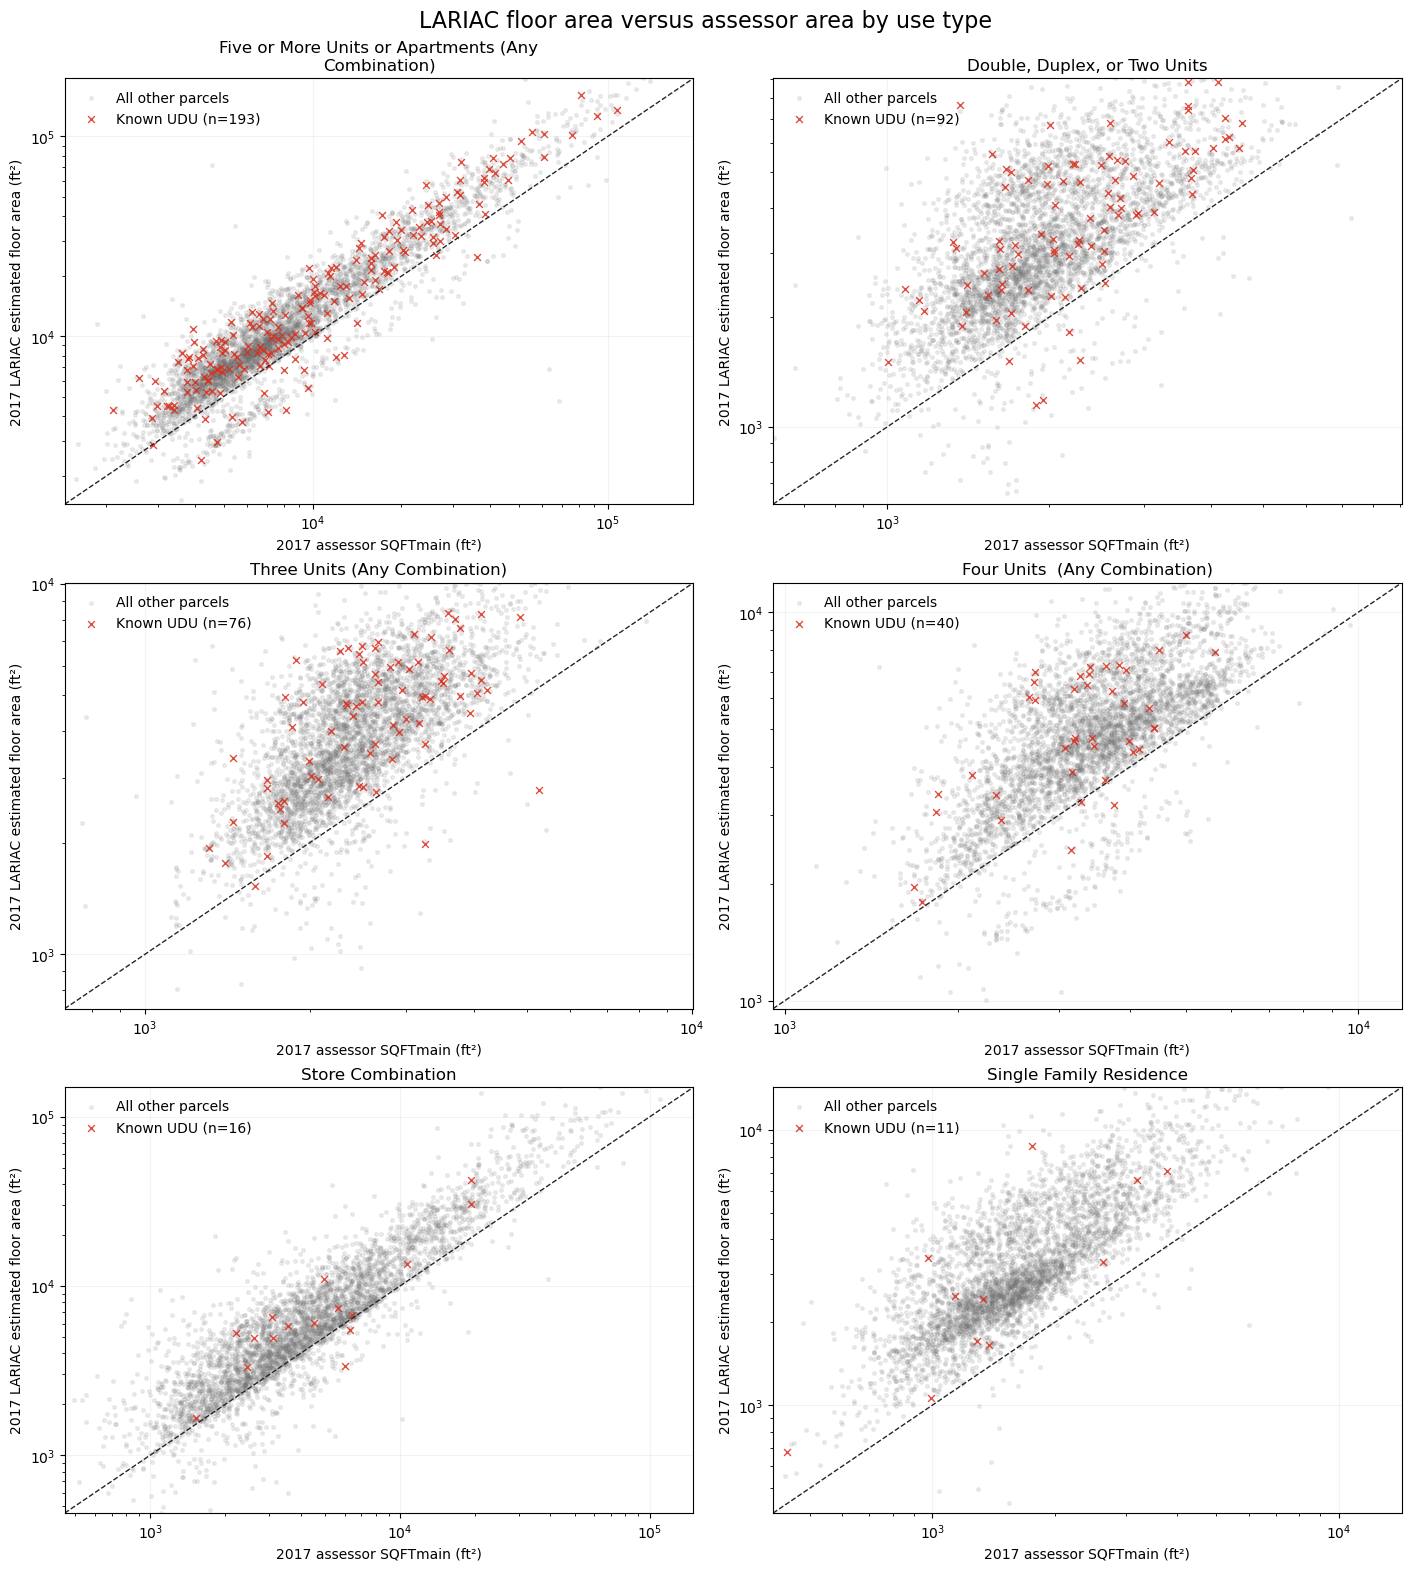

In [3]:
ncols = 2
nrows = int(np.ceil(len(modeled_use_types) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 5.2 * nrows), constrained_layout=True
)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, modeled_use_types):
    group = method1_input.loc[method1_input['SpecificUseType'].eq(use_type)]
    other = group.loc[~group['is_known_udu']]
    if len(other) > 4000:
        other = other.sample(4000, random_state=42)
    known = group.loc[group['is_known_udu']]
    ax.scatter(
        other['assessor.sqft'], other['building.floor_area'],
        s=7, alpha=0.12, color='#737373', rasterized=True,
        label='All other parcels',
    )
    ax.scatter(
        known['assessor.sqft'], known['building.floor_area'],
        s=24, alpha=0.85, color='#d7301f', marker='x', linewidth=1.0,
        label=f'Known UDU (n={len(known):,})',
    )
    values = pd.concat([
        group['assessor.sqft'], group['building.floor_area']
    ]).dropna()
    lower = max(10, float(values.quantile(0.001)))
    upper = float(values.quantile(0.995))
    ax.plot([lower, upper], [lower, upper], '--', color='#252525', linewidth=1)
    ax.set(xscale='log', yscale='log', xlim=(lower, upper), ylim=(lower, upper))
    ax.set_title('\n'.join(textwrap.wrap(use_type, 42)))
    ax.set_xlabel('2017 assessor SQFTmain (ft²)')
    ax.set_ylabel('2017 LARIAC estimated floor area (ft²)')
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, loc='upper left')
for ax in axes[len(modeled_use_types):]:
    ax.remove()
fig.suptitle('LARIAC floor area versus assessor area by use type', fontsize=16)
plt.show()

In [22]:
def build_method1_features(
    data,
    percentile_cutoff=0.025,
    minimum_raw_residual=0.0,
    ratio_percentile_cutoff=0.05,
    *,
    ain_col='AIN',
    use_type_col='SpecificUseType',
    lariac_floor_area_col='building.floor_area',
    assessor_area_col='assessor.sqft',
):
    """Build Method 1 agreement features at the single-AIN parcel level.

    Two screens are retained side by side. The residual screen flags the
    closest absolute agreement within use type. The ratio screen flags the
    lowest LARIAC floor area / assessor SQFTmain within use type: parcels
    where the assessor records at least as much area as the imagery shows,
    leaving the least room for unrecorded space.
    """
    required = {
        ain_col, use_type_col, lariac_floor_area_col, assessor_area_col
    }
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Missing Method 1 columns: {sorted(missing)}')

    features = data[[ain_col, use_type_col]].copy()
    features['raw_residual_sqft'] = (
        data[lariac_floor_area_col] - data[assessor_area_col]
    )
    features['_absolute_residual_sqft'] = features['raw_residual_sqft'].abs()
    features['abs_residual_pct_rank_by_use_type'] = (
        features.groupby(use_type_col)['_absolute_residual_sqft']
        .rank(method='average', pct=True)
    )
    features['method1_potential_nonudu'] = (
        features['abs_residual_pct_rank_by_use_type'].le(percentile_cutoff)
        & features['raw_residual_sqft'].gt(minimum_raw_residual)
    )
    features['floor_area_to_sqft_ratio'] = (
        data[lariac_floor_area_col]
        / data[assessor_area_col].where(data[assessor_area_col].gt(0))
    )
    features['log_floor_area_to_sqft_ratio'] = np.log(features['floor_area_to_sqft_ratio'])
    features['ratio_pct_rank_by_use_type'] = (
        features.groupby(use_type_col)['floor_area_to_sqft_ratio']
        .rank(method='average', pct=True)
    )
    features['method1_ratio_potential_nonudu'] = (
        features['ratio_pct_rank_by_use_type'].le(ratio_percentile_cutoff)
    )
    return (
        features[[
            ain_col, 'raw_residual_sqft',
            'abs_residual_pct_rank_by_use_type', 'method1_potential_nonudu',
            'floor_area_to_sqft_ratio', 'log_floor_area_to_sqft_ratio','ratio_pct_rank_by_use_type',
            'method1_ratio_potential_nonudu',
        ]]
        .rename(columns={ain_col: 'AIN'})
        .sort_values('AIN')
        .reset_index(drop=True)
    )

method1_features = build_method1_features(method1_input)
method1_output = method1_features[['AIN', 'method1_potential_nonudu']].copy()
display(pd.Series({
    'Output AINs': len(method1_features),
    'Residual screen potential non-UDU AINs': int(method1_features['method1_potential_nonudu'].sum()),
    'Residual screen share': method1_features['method1_potential_nonudu'].mean(),
    'Ratio screen potential non-UDU AINs': int(method1_features['method1_ratio_potential_nonudu'].sum()),
    'Ratio screen share': method1_features['method1_ratio_potential_nonudu'].mean(),
    'AINs flagged by both screens': int((
        method1_features['method1_potential_nonudu']
        & method1_features['method1_ratio_potential_nonudu']
    ).sum()),
}).to_frame('value'))
known_udu_flags = method1_features.loc[
    method1_features['AIN'].isin(known_udu_ains)
]
display(pd.Series({
    'Known UDU AINs': len(known_udu_flags),
    'Known UDU flagged by residual screen': int(known_udu_flags['method1_potential_nonudu'].sum()),
    'Known UDU flagged by ratio screen': int(known_udu_flags['method1_ratio_potential_nonudu'].sum()),
}).to_frame('value'))
display(method1_features.head())
display(method1_output.head())

# Deliberately not saved during method development. When finalized:
# output_path = CITY_OUTPUT / 'method1_potential_nonudu_2017.parquet'
# output_path.parent.mkdir(parents=True, exist_ok=True)
# method1_output.to_parquet(output_path, index=False)

,value
Output AINs,556277.000000
Residual screen potential non-UDU AINs,11027.000000
Residual screen share,0.019823
Ratio screen potential non-UDU AINs,27811.000000
Ratio screen share,0.049995
AINs flagged by both screens,9169.000000


,value
Known UDU AINs,428
Known UDU flagged by residual screen,5
Known UDU flagged by ratio screen,24


,AIN,raw_residual_sqft,abs_residual_pct_rank_by_use_type,method1_potential_nonudu,floor_area_to_sqft_ratio,log_floor_area_to_sqft_ratio,ratio_pct_rank_by_use_type,method1_ratio_potential_nonudu
0,2004001003,6599.54,0.974978,False,4.157675,1.424956,0.983825,False
1,2004001004,2903.04,0.815849,False,2.171053,0.775212,0.716368,False
2,2004001005,5172.18,0.951258,False,3.514429,1.256877,0.958115,False
3,2004001008,3759.52,0.892882,False,2.551597,0.93672,0.815889,False
4,2004001009,3791.58,0.894926,False,2.703315,0.994479,0.846926,False


,AIN,method1_potential_nonudu
0,2004001003,False
1,2004001004,False
2,2004001005,False
3,2004001008,False
4,2004001009,False


In [ ]:
# AIN-level scores for the cross-method comparison in notebook 04. This is an
# intermediate file, separate from the final output above.
METHOD_SCORES_DIR = PROJECT_ROOT / 'data/02_intermediate/method_scores'
METHOD_SCORES_DIR.mkdir(parents=True, exist_ok=True)
method1_features.to_parquet(METHOD_SCORES_DIR / 'method1_scores_2017.parquet', index=False)
print(f'Saved {len(method1_features):,} AIN rows to {METHOD_SCORES_DIR / "method1_scores_2017.parquet"}')

## Spatial pattern of agreement

AIN center points come from `all_parcel_data` (2016 roll centers, the closest available to 2017, falling back to 2024) and are aggregated into hexagons, so that hundreds of thousands of AINs render quickly. `plot_ain_hexbin` accepts any DataFrame with an AIN column and a numeric or boolean metric column. Each hexagon shows the metric reduced over its AINs (the median by default). Hexagons with fewer than `min_count` AINs are left blank.

In [5]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import plot_ain_hexbin
from src.viz import AIN_POINT_CRS


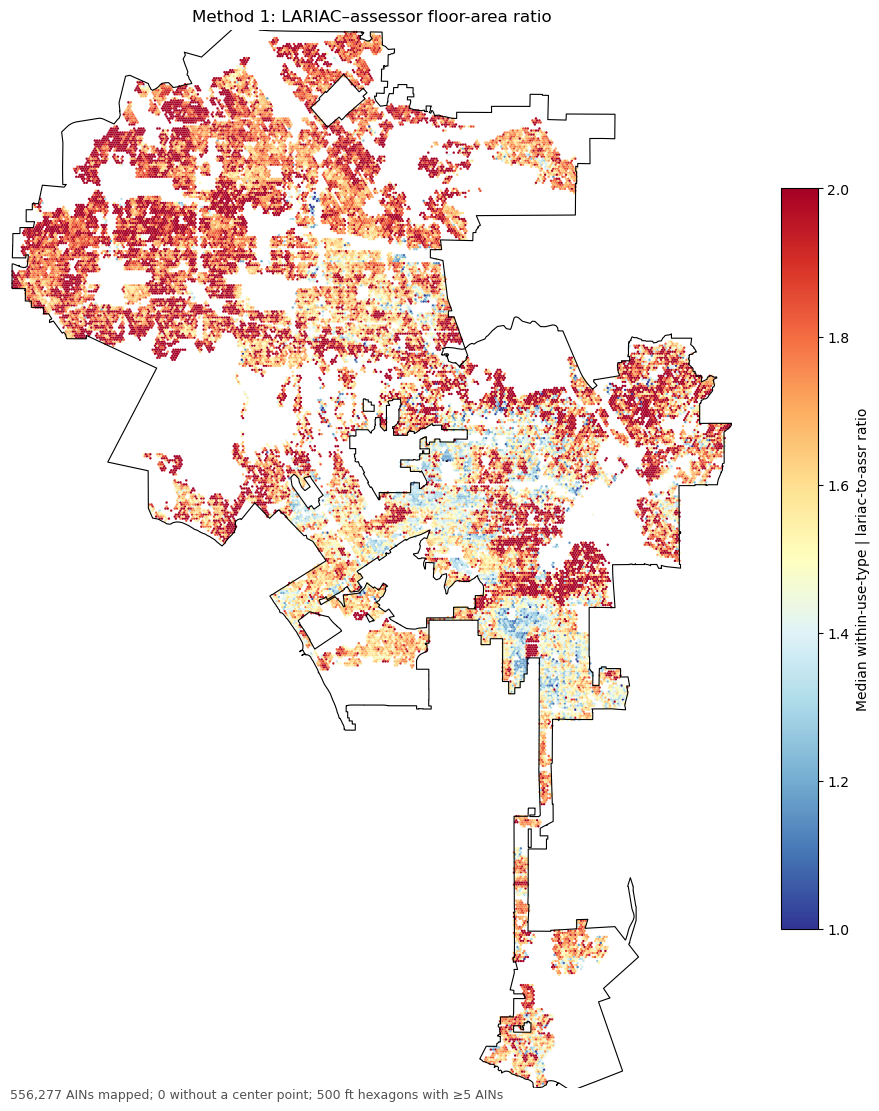

In [25]:
# Ranks are uniform within each use type, so 0.5 is the citywide expectation:
# blue hexagons agree more closely than is typical for their use types, red less.
fig, ax = plt.subplots(figsize=(11, 11), constrained_layout=True)

plot_ain_hexbin(
    method1_features, 'floor_area_to_sqft_ratio',ax = ax,
    cmap='RdYlBu_r', 
    # scheme = 'quantiles',
    vmin=1, vmax=2,
    hex_width_ft = 500,
    title='Method 1: LARIAC–assessor floor-area ratio',
    colorbar_label='Median within-use-type | lariac-to-assr ratio',
)

import geopandas as gpd
# GeoJSON is WGS84; the hexbins are in EPSG:2229 feet.
lac = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson')
xlim, ylim = ax.get_xlim(), ax.get_ylim()
lac.to_crs(AIN_POINT_CRS).boundary.plot(ax=ax, color='k', linewidth=0.8)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()
